CRTANJE

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

print(listings.shape)

(4574, 73)


** Notes: the wordsto remember
- figure: the whole picture,like a sheet of paper.
- axes(ax): one chart on the figure, with its own x-axis and y-axis.
- fig, ax  = plt.subplots(): makes a new figure with one axeo on it. We draw on the axes.
- histogram: divides the values into intervals and counts how many fall in each one.
- bins: the intervals of a histogram. More bins give a more detailed picture.
- dropna(): removes the missing values. A chart can only draw what exists.
- plt.show(): shows the picture.

** What does the distribution of the price look like?

histogram

In [ ]:
fig, ax = plt.subplots()

ax.hist(listings['price'].dropna(), bins=50)

plt.show()

NameError: name 'plt' is not defined

In [ ]:
pip install matplotlib seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.5 MB 11.6 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.5 MB 11.7 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.5 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 8.2 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 8.2 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   -------------- ------------------------- 2.6/7.3 MB 11.7 MB/s eta 0:00:01
   --------------------------- ------------ 5.0/7.3 MB 11.7 MB/s eta 0:00:01
   ----------------------------

In [ ]:
fig, ax = plt.Subplot()

sns.histplot(data=listings, x='price', bins=50, ax=ax)

ax.set_title

ax.set_ylabel('Number of listings')

plt.show()

------- FALI imas u .doc 9:30

The histogra. see the shape of the price

In [ ]:
q1 = listings['price'].quantile(0.25)
q3 = listings['price'].quantile(0.75)
upper = q3 + 1.5 * (q3-q1)

listings['ptivr<-ouylirt'] = listings['price']> upper
print(round(upper,1), listings['price_outlier'].sum())

NameError: name 'listings' is not defined

In [ ]:
median = listings['price'].median()
mean = listings ['price'].mean()

fig, ax = plt.subplots()

sns.histplot(data=listngs, x='price', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}'))
ax.axvline(median, color='red', linestyle='--', label=f'mean {mean:,.0f}'))
ax.axvline(median, color='gray', linestyle='--', label=f'upper fence {upper:,.0f}'))

ax.set_title('The mean is pulled to the rigth by the long tail')
ax.set_xlabel('Price per night')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()

In [ ]:
#9:46 - PROBLEM - proveri koc

fig, axex = plt.subplots(1, 2, figsize=(12,4)  # 12,4 inches - one chart - two sheets
sns.histplot(data=listngs, x='price', bins=50, ax=ax)
sns.histplot(data=listngs[~listings['price_outlier']], x='price', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Witholut the 132 outliers')

for ax.in axes:
    ax.set_xlabel('Price per night')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()


ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}'))
ax.axvline(median, color='red', linestyle='--', label=f'mean {mean:,.0f}'))
ax.axvline(median, color='gray', linestyle='--', label=f'upper fence {upper:,.0f}'))

ax.set_title('The mean is pulled to the rigth by the long tail')
ax.set_xlabel('Price per night')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()

## The boxplot : see the outliers

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))

sns.boxplot(data(listings, x='price'), ax=ax)

ax.set_title('The boxplot of the price')
ax.set_xlabel('Price per night')

plt.show()

# Ovo je na osnovu IQR rula od juce

In [ ]:
two_types = listings['listings['room_type].isin(['Entire home/apt', 'Private room'])']

fig, ax = plt.subplots(figsize=(8,5))

sns.boxplot(data=two_types, x='room_type', y='price', ax=ax)

ax.set_ylim(0,8000)
ax.set_title('An entire home costs much more then a private room\n(prices above 8,000 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Price per night')

plt.show()

## Bar chart: compare the neighbourhoods

Koliko lista ima u ... i za to nam je potrebno... 10:27

In [ ]:
order = listings['neighbourhood_cleansed'].value_counts().index

fig, ax = plt.subplots(figsize=(8,5))

sns.countplot(data=listings, y='neighbourhood_cleansed', order=order, ax=ax)

ax.set_title('Södermalms has by far the most listings')
ax.set_xlabel('Number of listings')
ax.setylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# 10:35

by_area =(
    listings.groupby('neighbourhood_cleansed')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .rest_index()
)

by_area['label'] = by_area['neighbourhood_cleansed'] + '(' + by_area['count'].astype(str) +')' # Farsta(113)

by_area.head(3)

In [ ]:
fif, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x='median', y='label', ax=ax)

ax.set_title('Median price per night (the numer of listings wiht a price in brackets)')
ax.set_xlabel('Median price per night')
ax.setylabel('')

plt.tight_layout()
plt.show()

## The scatter plot: how two columns move together

In [ ]:
print((listings['price'] > 12000).sum(), 'listings are above the top of the picture')

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=listings, x='axxommodates', y='price', ax=ax)

ax.set_ylim(0, 12000)

ax.set_title('Listings for more guests cost more, but the spread is large')
ax.set_xlabel('Number of guests')
ax.setylabel('Price per night')

plt.show()

Svaka tacka je listing, a svaki oblak je listing sa vise gostiju - i ovde cemo koristiti alfa parametar (alfa(0,3) je 30% solidan)

In [ ]:
medians = listings.groupby('accommodates')['price'].median().head(10)

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=listings, x='axxommodates', y='price', alpha=0.3 ax=ax)

ax.plot(medians.index, medians.values, color='red', marker= 'o', label='median price (1 to 10 guests)')

ax.set_ylim(0, 12000)

ax.set_title('The median price rises with the number of guests')
ax.set_xlabel('Number of guests')
ax.setylabel('Price per night')

plt.show()

NameError: name 'two_types' is not defined

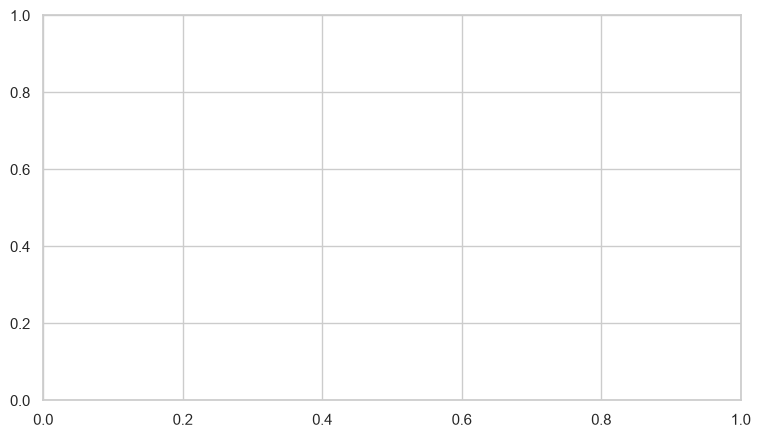

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=two_types, x='accommodates', y='price', hue='room_type', alpha=0.4, ax=ax)

ax.set_ylim(0, 12000)

ax.set_title('Entire homes are above private rooms for the same number of guests')
ax.set_xlabel('Number of guests')
ax.sety_label('Price per night')

# dobicemo dve boje na grafiju za entire home/apt i za private room

## The heatmap and the line chart

Kako ce 7 kolona da se slaze medjusobno? 
Stavicemo ih u tabelu, tako da je svaka celija u korelaciji...
49 brojeva (7*7) - malo je tesko da se cita, ali cemo naci metodu...
Stavicemo u svaku celiju boju za neku vrednost (7 boja) da bi se video patern.
To je jedna vrsta specijalnosti CBOARD-a


In [ ]:
column = ['price', 'accommodates', 'bedrooms', 'beds', 'number_of_review', 'availability_365', 'review_scores_rating']

corr= listings[column].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)

ax.set_title('How the columns move together')

plt.tight_layout()
plt.show()

When did the listings get their firs review?

lineplot

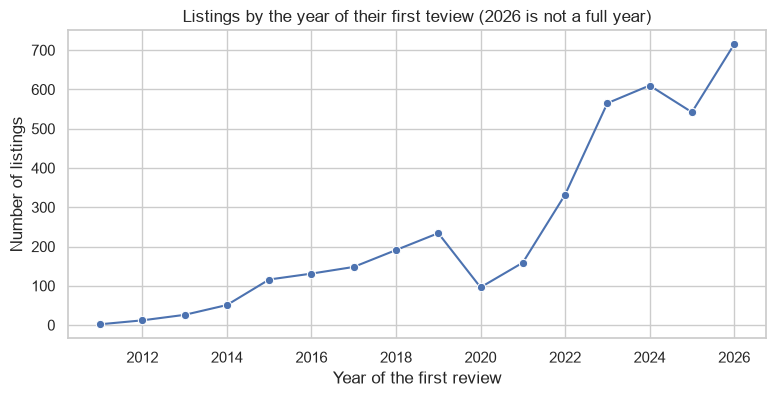

In [20]:
per_year = listings['first_review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9,4))

sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax=ax)

ax.set_title('Listings by the year of their first teview (2026 is not a full year)')
ax.set_xlabel('Year of the first review')
ax.set_ylabel('Number of listings')

plt.show()

## A good chart, and a chart that lies

Ono sto razlikuje dobar od loseg chart-a je 

In [ ]:
superhost = listings.groupby('host_is_superhost')['price'].median()

# pocinje da pada prvi sneg ove godine 11:48 2026-11-18
fig, ax = plt.subplots(1, 2, figsize= (11, 4))

for ax in axes:
    sns.barplot(x=['Other hosts', 'Superhost'], y=superhost.values, ax=ax)
    ax.set_ylabel('Median price per night')

    axes[0].set_title('Axis form 0')
    axes[1].set_title('Axis form 1600')
    axes[1].set_ylim(1600, 1850)

    plt.tight_layout()
    plt.show()
        
        
    

- A title that says what we see, not just what it is.
- Names on both axes, and the unit when there is one.
- One colour, unless the colour means something, and never colour only ofr decoration.
- Bars start at zero, and are sorted.
- Say what you left out: the missing values, the cut-of axis, the outliers. And say how many listings are behind the picture.
- Do not draw what you cannot read: too many categories, too many colours, 3D effects.

In [ ]:
fig, ax = p prepisi ovo 11:57